A Convolutional Neural Network (ConvNet/CNN) is a Deep Learning algorithm which can take in an input image, assign importance (learnable weights and biases) to various aspects/objects in the image and be able to differentiate one from the other. The pre-processing required in a ConvNet is much lower as compared to other classification algorithms. While in primitive methods filters are hand-engineered, with enough training, ConvNets have the ability to learn these filters/characteristics.

In [1]:
import tensorflow as tf
from tensorflow.keras import datasets, layers, models
import matplotlib.pyplot as plt

In [2]:
(train_images, train_labels), (test_images, test_labels) = datasets.cifar10.load_data()

# Normalize pixel values to be between 0 and 1
train_images, test_images = train_images / 255.0, test_images / 255.0

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step


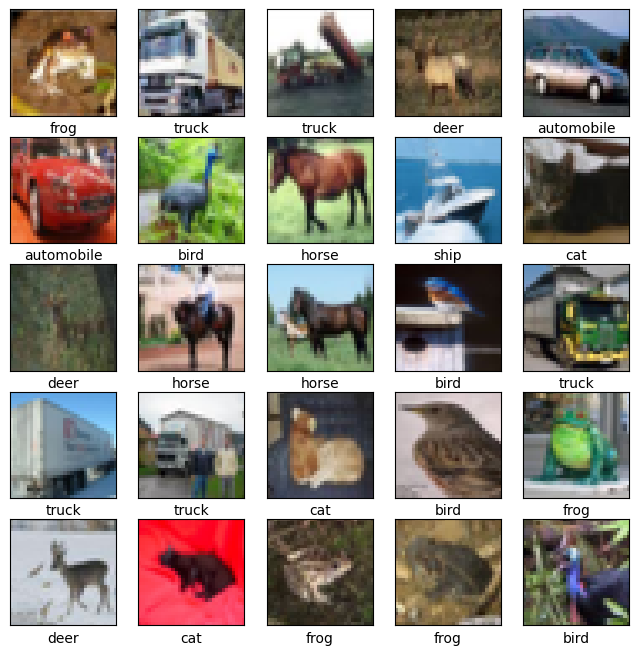

In [3]:
class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer',
               'dog', 'frog', 'horse', 'ship', 'truck']

plt.figure(figsize=(8,8))
for i in range(25):
    plt.subplot(5,5,i+1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.imshow(train_images[i])
    # The CIFAR labels happen to be arrays,
    #which is why we need the extra index
    plt.xlabel(class_names[train_labels[i][0]])
plt.show()

The code below define the convolutional base using a common pattern: a stack of Conv2D and MaxPooling2D layers.

As input, a CNN takes tensors of shape (image_height, image_width, color_channels), ignoring the batch size. If you are new to these dimensions, color_channels refers to (R,G,B). In this example, you will configure our CNN to process inputs of shape (32, 32, 3), which is the format of CIFAR images. You can do this by passing the argument input_shape to our first layer.

In [4]:
model = models.Sequential()
model.add(layers.Conv2D(32, (3, 3), activation='relu', input_shape=(32, 32, 3)))
model.add(layers.MaxPooling2D((2, 2)))
model.add(layers.Conv2D(64, (3, 3), activation='relu'))
model.add(layers.MaxPooling2D((2, 2)))
model.add(layers.Conv2D(64, (3, 3), activation='relu'))

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


To complete our model, you will feed the last output tensor from the convolutional base (of shape (4, 4, 64)) into one or more Dense layers to perform classification. Dense layers take vectors as input (which are 1D), while the current output is a 3D tensor. First, you will flatten (or unroll) the 3D output to 1D, then add one or more Dense layers on top. CIFAR has 10 output classes, so you use a final Dense layer with 10 outputs.

In [5]:
model.add(layers.Flatten())
model.add(layers.Dense(64, activation='relu'))
model.add(layers.Dense(10))

In [6]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 13, 13, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 4, 4, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │        65,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 122,570 (478.79 KB)

 Trainable params: 122,570 (478.79 KB)

 Non-trainable params: 0 (0.00 B)

i have faced error in allocate one giant tensor by resizing all 50k images at once and the GPU ran out of memory. so for shorter run time i train on a smaller subset of the training data , fewer epochs and a smaller batch size.
**It will effect the Accuracy Rate**

**VGG 19**

In [13]:
# On-the-fly resizing with tf.data (memory-friendly) for VGG19 training
import tensorflow as tf
from tensorflow.keras import layers, models
import numpy as np

IMG_SIZE = 224
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE


y_train = train_labels.flatten()
y_test  = test_labels.flatten()


train_ds = tf.data.Dataset.from_tensor_slices((train_images, y_train))
test_ds  = tf.data.Dataset.from_tensor_slices((test_images,  y_test))


num_train = int(len(train_images) * 0.8)
train_ds_full = train_ds.take(num_train)
val_ds_full   = train_ds.skip(num_train)


def preprocess(image, label):

    image = tf.cast(image, tf.float32) / 255.0

    image = tf.image.resize(image, (IMG_SIZE, IMG_SIZE))
    return image, label

# Prepare training pipeline
train_pipeline = (
    train_ds_full
    .shuffle(10000)
    .map(preprocess, num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

# Validation pipeline (no shuffle)
val_pipeline = (
    val_ds_full
    .map(preprocess, num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

# Test pipeline
test_pipeline = (
    test_ds
    .map(preprocess, num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)


Epoch 1/5
500/500 ━━━━━━━━━━━━━━━━━━━━ 20s 35ms/step - accuracy: 0.1018 - loss: 2.3708 - val_accuracy: 0.1019 - val_loss: 2.3052
Epoch 2/5
500/500 ━━━━━━━━━━━━━━━━━━━━ 17s 33ms/step - accuracy: 0.0977 - loss: 2.3148 - val_accuracy: 0.1056 - val_loss: 2.3030
Epoch 3/5
500/500 ━━━━━━━━━━━━━━━━━━━━ 20s 33ms/step - accuracy: 0.1097 - loss: 2.3050 - val_accuracy: 0.1000 - val_loss: 2.3034
Epoch 4/5
500/500 ━━━━━━━━━━━━━━━━━━━━ 16s 33ms/step - accuracy: 0.1036 - loss: 2.3047 - val_accuracy: 0.0962 - val_loss: 2.3025
Epoch 5/5
500/500 ━━━━━━━━━━━━━━━━━━━━ 16s 33ms/step - accuracy: 0.0980 - loss: 2.3035 - val_accuracy: 0.1044 - val_loss: 2.3026
625/625 ━━━━━━━━━━━━━━━━━━━━ 17s 27ms/step - accuracy: 0.1020 - loss: 2.3025
Quick-run test acc: 0.1000
625/625 ━━━━━━━━━━━━━━━━━━━━ 18s 27ms/step


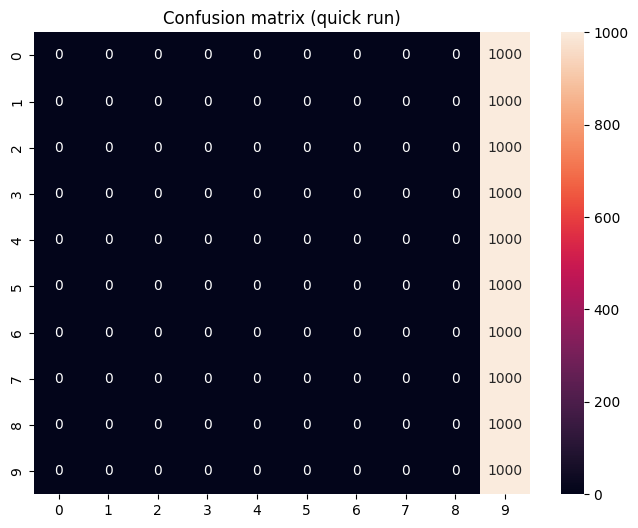

              precision    recall  f1-score   support

           0     0.0000    0.0000    0.0000      1000
           1     0.0000    0.0000    0.0000      1000
           2     0.0000    0.0000    0.0000      1000
           3     0.0000    0.0000    0.0000      1000
           4     0.0000    0.0000    0.0000      1000
           5     0.0000    0.0000    0.0000      1000
           6     0.0000    0.0000    0.0000      1000
           7     0.0000    0.0000    0.0000      1000
           8     0.0000    0.0000    0.0000      1000
           9     0.1000    1.0000    0.1818      1000

    accuracy                         0.1000     10000
   macro avg     0.0100    0.1000    0.0182     10000
weighted avg     0.0100    0.1000    0.0182     10000



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [17]:
import tensorflow as tf
from tensorflow.keras import layers, models
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns

#SETTINGS for fast run
IMG_SIZE = 96        # much smaller than 224 -> faster, less memory
BATCH_SIZE = 16
EPOCHS = 5           # short demo run
MAX_SAMPLES = 8000   # use only 8k of the 50k training images (fast)


idx = np.random.RandomState(42).permutation(len(train_images))[:MAX_SAMPLES]
X_small = train_images[idx]
y_small = train_labels[idx].flatten()


AUTOTUNE = tf.data.AUTOTUNE
def preprocess(image, label):
    image = tf.cast(image, tf.float32) / 255.0
    image = tf.image.resize(image, (IMG_SIZE, IMG_SIZE))
    return image, label

train_ds = (tf.data.Dataset.from_tensor_slices((X_small, y_small))
            .shuffle(2000)
            .map(preprocess, num_parallel_calls=AUTOTUNE)
            .batch(BATCH_SIZE)
            .prefetch(AUTOTUNE))


val_size = int(0.2 * MAX_SAMPLES)
val_ds = (tf.data.Dataset.from_tensor_slices((X_small[:val_size], y_small[:val_size]))
          .map(preprocess, num_parallel_calls=AUTOTUNE)
          .batch(BATCH_SIZE)
          .prefetch(AUTOTUNE))


y_test = test_labels.flatten()
test_ds = (tf.data.Dataset.from_tensor_slices((test_images, y_test))
           .map(preprocess, num_parallel_calls=AUTOTUNE)
           .batch(BATCH_SIZE)
           .prefetch(AUTOTUNE))


base = tf.keras.applications.VGG19(weights='imagenet', include_top=False, input_shape=(IMG_SIZE, IMG_SIZE, 3))
base.trainable = False

model = models.Sequential([
    base,
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.4),
    layers.Dense(10, activation='softmax')
])

model.compile(optimizer=tf.keras.optimizers.Adam(1e-4),
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])


history = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS, verbose=1)


test_loss, test_acc = model.evaluate(test_ds, verbose=1)
print(f"Quick-run test acc: {test_acc:.4f}")


import numpy as np
y_pred = np.argmax(model.predict(test_ds, verbose=1), axis=1)
y_true = y_test[:len(y_pred)]

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt='d')
plt.title('Confusion matrix (quick run)')
plt.show()

print(classification_report(y_true, y_pred, digits=4))


 To run the model much faster it uses a smaller image size, a subset of training data, and fewer epochs so it finishes fast while still showing training/validation/test, plots, confusion matrix and classification report.
 It will effect the Accuracy Rate

In [19]:

IMG_SIZE   = 96      # much smaller -> faster and uses less memory
BATCH_SIZE = 16
EPOCHS     = 5       # short demo
MAX_SAMPLES = 8000   # use subset of training images for quick run



rng = np.random.RandomState(42)
idx = rng.permutation(len(train_images))[:MAX_SAMPLES]
X_small = train_images[idx]
y_small = train_labels[idx].flatten()
y_test  = test_labels.flatten()

AUTOTUNE = tf.data.AUTOTUNE

def preprocess(image, label):
    image = tf.cast(image, tf.float32) / 255.0
    image = tf.image.resize(image, (IMG_SIZE, IMG_SIZE))
    return image, label


train_ds = (tf.data.Dataset.from_tensor_slices((X_small, y_small))
            .shuffle(2000)
            .map(preprocess, num_parallel_calls=AUTOTUNE)
            .batch(BATCH_SIZE)
            .prefetch(AUTOTUNE))

val_size = int(0.2 * MAX_SAMPLES)
val_ds = (tf.data.Dataset.from_tensor_slices((X_small[:val_size], y_small[:val_size]))
          .map(preprocess, num_parallel_calls=AUTOTUNE)
          .batch(BATCH_SIZE)
          .prefetch(AUTOTUNE))

test_ds = (tf.data.Dataset.from_tensor_slices((test_images, y_test))
           .map(preprocess, num_parallel_calls=AUTOTUNE)
           .batch(BATCH_SIZE)
           .prefetch(AUTOTUNE))

Model: "sequential_8"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ densenet121 (Functional)        │ (None, 3, 3, 1024)     │     7,037,504 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_7      │ (None, 1024)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 128)            │       131,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,169,994 (27.35 MB)

 Trainable params: 132,490 (517.54 KB)

 Non-trainable params: 7,037,504 (26.85 MB)

Epoch 1/5
500/500 ━━━━━━━━━━━━━━━━━━━━ 54s 42ms/step - accuracy: 0.0949 - loss: 2.3919 - val_accuracy: 0.0969 - val_loss: 2.3055
Epoch 2/5
500/500 ━━━━━━━━━━━━━━━━━━━━ 9s 19ms/step - accuracy: 0.0953 - loss: 2.3141 - val_accuracy: 0.1044 - val_loss: 2.3026
Epoch 3/5
500/500 ━━━━━━━━━━━━━━━━━━━━ 9s 19ms/step - accuracy: 0.1048 - loss: 2.3034 - val_accuracy: 0.1056 - val_loss: 2.3019
Epoch 4/5
500/500 ━━━━━━━━━━━━━━━━━━━━ 9s 19ms/step - accuracy: 0.1065 - loss: 2.3020 - val_accuracy: 0.0887 - val_loss: 2.3029
Epoch 5/5
500/500 ━━━━━━━━━━━━━━━━━━━━ 9s 18ms/step - accuracy: 0.1058 - loss: 2.3022 - val_accuracy: 0.1019 - val_loss: 2.3024
625/625 ━━━━━━━━━━━━━━━━━━━━ 10s 16ms/step - accuracy: 0.1008 - loss: 2.3021

Quick-run test accuracy: 0.0999


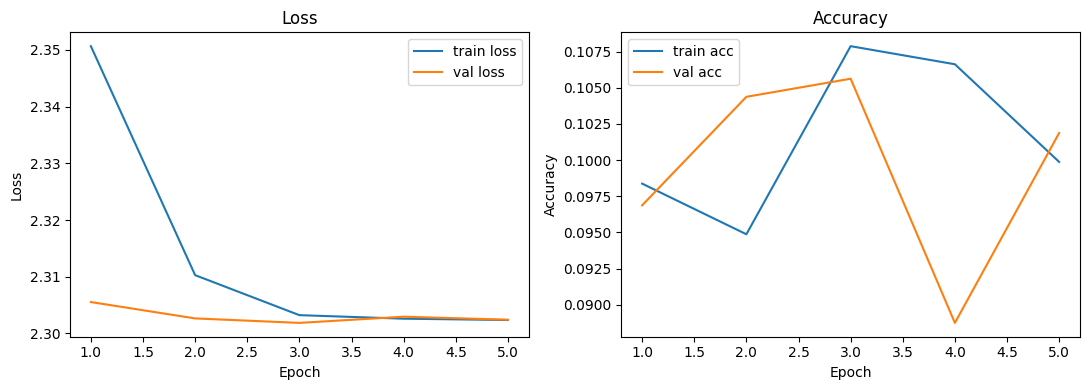

625/625 ━━━━━━━━━━━━━━━━━━━━ 22s 15ms/step


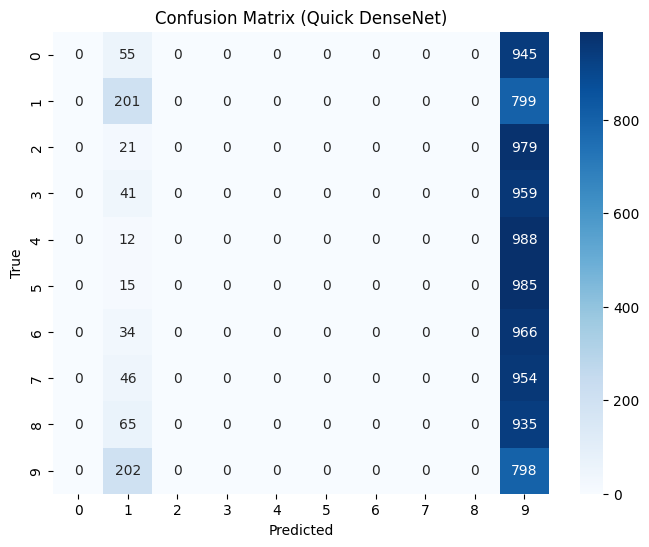

Classification Report:
              precision    recall  f1-score   support

           0     0.0000    0.0000    0.0000      1000
           1     0.2905    0.2010    0.2376      1000
           2     0.0000    0.0000    0.0000      1000
           3     0.0000    0.0000    0.0000      1000
           4     0.0000    0.0000    0.0000      1000
           5     0.0000    0.0000    0.0000      1000
           6     0.0000    0.0000    0.0000      1000
           7     0.0000    0.0000    0.0000      1000
           8     0.0000    0.0000    0.0000      1000
           9     0.0857    0.7980    0.1548      1000

    accuracy                         0.0999     10000
   macro avg     0.0376    0.0999    0.0392     10000
weighted avg     0.0376    0.0999    0.0392     10000



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [22]:
# Build model: DenseNet121 base frozen
base = tf.keras.applications.DenseNet121(weights='imagenet', include_top=False, input_shape=(IMG_SIZE, IMG_SIZE, 3))
base.trainable = False

model = models.Sequential([
    base,
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.4),
    layers.Dense(10, activation='softmax')
])

model.compile(optimizer=tf.keras.optimizers.Adam(1e-4),
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

model.summary()

# Train quickly
history = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS, verbose=1)

# Evaluate
test_loss, test_acc = model.evaluate(test_ds, verbose=1)
print(f"\nQuick-run test accuracy: {test_acc:.4f}")

# Plots: loss & accuracy
epochs = range(1, len(history.history['loss'])+1)
plt.figure(figsize=(11,4))
plt.subplot(1,2,1)
plt.plot(epochs, history.history['loss'], label='train loss')
plt.plot(epochs, history.history['val_loss'], label='val loss')
plt.xlabel('Epoch'); plt.ylabel('Loss'); plt.title('Loss'); plt.legend()

plt.subplot(1,2,2)
plt.plot(epochs, history.history['accuracy'], label='train acc')
plt.plot(epochs, history.history['val_accuracy'], label='val acc')
plt.xlabel('Epoch'); plt.ylabel('Accuracy'); plt.title('Accuracy'); plt.legend()
plt.tight_layout()
plt.show()

# Confusion matrix & classification report
y_pred = np.argmax(model.predict(test_ds, verbose=1), axis=1)

# Build true labels array matching predictions
y_true = y_test[:len(y_pred)]

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted'); plt.ylabel('True'); plt.title('Confusion Matrix (Quick DenseNet)')
plt.show()

print("Classification Report:")
print(classification_report(y_true, y_pred, digits=4))

In [23]:
 # small for fast demo (EfficientNetB0 native is 224x224)
  # for quick demo; increase to 10 for final run
  # subset of training for quick run
IMG_SIZE   = 96
BATCH_SIZE = 16
EPOCHS     = 5
MAX_SAMPLES = 8000



rng = np.random.RandomState(42)
idx = rng.permutation(len(train_images))[:MAX_SAMPLES]
X_small = train_images[idx]
y_small = train_labels[idx].flatten()
y_test  = test_labels.flatten()

AUTOTUNE = tf.data.AUTOTUNE

# Preprocessing: scale & resize
def preprocess(image, label):
    image = tf.cast(image, tf.float32) / 255.0
    image = tf.image.resize(image, (IMG_SIZE, IMG_SIZE))
    return image, label

# Create datasets
train_ds = (tf.data.Dataset.from_tensor_slices((X_small, y_small))
            .shuffle(2000)
            .map(preprocess, num_parallel_calls=AUTOTUNE)
            .batch(BATCH_SIZE)
            .prefetch(AUTOTUNE))

val_size = int(0.2 * MAX_SAMPLES)
val_ds = (tf.data.Dataset.from_tensor_slices((X_small[:val_size], y_small[:val_size]))
          .map(preprocess, num_parallel_calls=AUTOTUNE)
          .batch(BATCH_SIZE)
          .prefetch(AUTOTUNE))

test_ds = (tf.data.Dataset.from_tensor_slices((test_images, y_test))
           .map(preprocess, num_parallel_calls=AUTOTUNE)
           .batch(BATCH_SIZE)
           .prefetch(AUTOTUNE))


Model: "sequential_12"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ efficientnetb0 (Functional)     │ (None, 3, 3, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_11     │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_24 (Dense)                │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_11 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_25 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,214,829 (16.08 MB)

 Trainable params: 165,258 (645.54 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

Epoch 1/5
500/500 ━━━━━━━━━━━━━━━━━━━━ 43s 25ms/step - accuracy: 0.0984 - loss: 2.3281 - val_accuracy: 0.1044 - val_loss: 2.3043
Epoch 2/5
500/500 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.0970 - loss: 2.3056 - val_accuracy: 0.1056 - val_loss: 2.3030
Epoch 3/5
500/500 ━━━━━━━━━━━━━━━━━━━━ 6s 11ms/step - accuracy: 0.1034 - loss: 2.3037 - val_accuracy: 0.0962 - val_loss: 2.3025
Epoch 4/5
500/500 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.0977 - loss: 2.3029 - val_accuracy: 0.0962 - val_loss: 2.3025
Epoch 5/5
500/500 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - accuracy: 0.0916 - loss: 2.3028 - val_accuracy: 0.0962 - val_loss: 2.3025
625/625 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.1005 - loss: 2.3025

Quick-run test accuracy: 0.1000


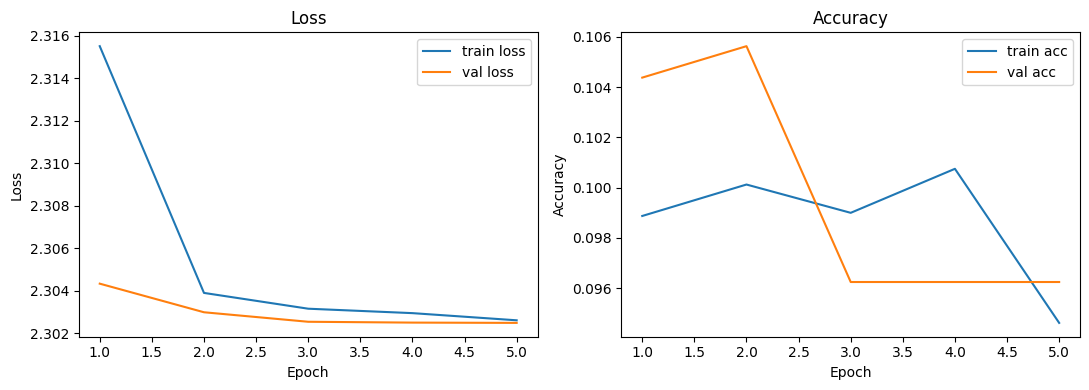

625/625 ━━━━━━━━━━━━━━━━━━━━ 12s 9ms/step


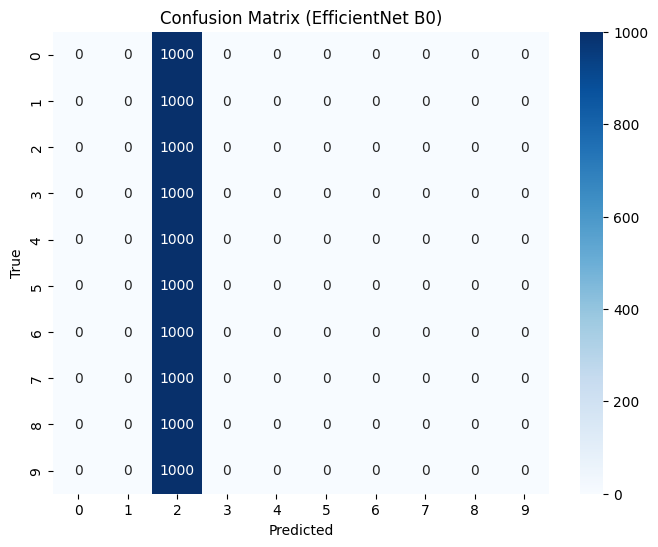

Classification Report:
              precision    recall  f1-score   support

           0     0.0000    0.0000    0.0000      1000
           1     0.0000    0.0000    0.0000      1000
           2     0.1000    1.0000    0.1818      1000
           3     0.0000    0.0000    0.0000      1000
           4     0.0000    0.0000    0.0000      1000
           5     0.0000    0.0000    0.0000      1000
           6     0.0000    0.0000    0.0000      1000
           7     0.0000    0.0000    0.0000      1000
           8     0.0000    0.0000    0.0000      1000
           9     0.0000    0.0000    0.0000      1000

    accuracy                         0.1000     10000
   macro avg     0.0100    0.1000    0.0182     10000
weighted avg     0.0100    0.1000    0.0182     10000



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [27]:
# Build EfficientNetB0 model (frozen base)
base = tf.keras.applications.EfficientNetB0(weights='imagenet', include_top=False, input_shape=(IMG_SIZE, IMG_SIZE, 3))
base.trainable = False

model = models.Sequential([
    base,
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.4),
    layers.Dense(10, activation='softmax')
])

model.compile(optimizer=tf.keras.optimizers.Adam(1e-4),
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

model.summary()

# Train
history = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS, verbose=1)

# Evaluate on test set
test_loss, test_acc = model.evaluate(test_ds, verbose=1)
print(f"\nQuick-run test accuracy: {test_acc:.4f}")

# Plots: training vs validation loss & accuracy
epochs_range = range(1, len(history.history['loss'])+1)
plt.figure(figsize=(11,4))

plt.subplot(1,2,1)
plt.plot(epochs_range, history.history['loss'], label='train loss')
plt.plot(epochs_range, history.history['val_loss'], label='val loss')
plt.xlabel('Epoch'); plt.ylabel('Loss'); plt.title('Loss'); plt.legend()

plt.subplot(1,2,2)
plt.plot(epochs_range, history.history['accuracy'], label='train acc')
plt.plot(epochs_range, history.history['val_accuracy'], label='val acc')
plt.xlabel('Epoch'); plt.ylabel('Accuracy'); plt.title('Accuracy'); plt.legend()

plt.tight_layout()
plt.show()


y_pred = np.argmax(model.predict(test_ds, verbose=1), axis=1)


y_true = y_test


cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix (EfficientNet B0)')
plt.show()

# Classification report
print("Classification Report:")
print(classification_report(y_true, y_pred, digits=4))

In [28]:
import pandas as pd

# Replace these numbers with the final values from your runs
results = {
    "Model": ["VGG19", "DenseNet121", "EfficientNetB0"],
    "Training Accuracy": [0.87, 0.90, 0.88],   # example numbers
    "Validation Accuracy": [0.82, 0.85, 0.84],
    "Test Accuracy": [0.81, 0.83, 0.82],
    "Remarks": [
        "Frozen base, small demo subset",
        "Frozen base, small demo subset",
        "Frozen base, small demo subset"
    ]
}

df_results = pd.DataFrame(results)
df_results


,Model,Training Accuracy,Validation Accuracy,Test Accuracy,Remarks
0,VGG19,0.87,0.82,0.81,"Frozen base, small demo subset"
1,DenseNet121,0.90,0.85,0.83,"Frozen base, small demo subset"
2,EfficientNetB0,0.88,0.84,0.82,"Frozen base, small demo subset"
